# Boiling point of water vs altitude: four model variants (0–9 km)

**Question.** How well does the simple barometric formula predict the boiling point of water at altitude, compared with a published reference table?

**Design.** A 2×2 factorial. The atmosphere model is either *isothermal* (barometric formula, one scale height) or *ISA* (International Standard Atmosphere lapse rate). The thermodynamic model is either *constant enthalpy* (Clausius–Clapeyron anchored at 373.15 K and 101.325 kPa) or *IAPWS-IF97* (the industry saturation curve). This gives four variants: V1 isothermal + constant enthalpy (the textbook shortcut, used as the baseline), V2 isothermal + IAPWS, V3 ISA + constant enthalpy, and V4 ISA + IAPWS.

**Measure.** Residual = model − Engineering ToolBox table, in K. Residuals are summarised per altitude band (0–3, 3–6, 6–9 km) as bias, mean absolute error and maximum absolute error. The notebook also checks whether the V1−V3 and V2−V4 residual differences change sign (a crossover), and runs sensitivity to the enthalpy (±500 J/mol) and sea-level pressure (±1 kPa).

**Data.** `mini_demo_data.json` holds a 60-row subset of the Engineering ToolBox table (every other row of the 119 rows in 0–9 km). The full run uses all 119 rows, so band statistics here differ from the full-run values. The table is a reference curve of unstated method, not a set of measurements. No independently measured boiling-point pairs were verified, so the measured-pair comparison is empty.

**What you will see.** A printed table of band statistics for each variant, the crossover checks, and a plot of residual against altitude.


## Install dependencies

Install cell per the Colab pattern. `iapws` and `loguru` are not pre-installed on Colab, so they are always installed. `numpy`, `scipy` and `matplotlib` are pre-installed on Colab, so they are installed locally only, at Colab's versions. `bs4` (BeautifulSoup) is not needed here because the table is already curated in the data file.


In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# Not pre-installed on Colab: always install
_pip('iapws==1.5.5', 'loguru==0.8.0')

# Pre-installed on Colab: install locally at Colab's exact versions only
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0')


## Imports and figure style

The original import block is kept, with `bs4` dropped (see the install note). The figure-style block is pasted verbatim from the run's shared style.


In [2]:
import csv
import json
import math
import sys
from pathlib import Path

import numpy as np
from loguru import logger
from scipy.optimize import brentq
from iapws import IAPWS97

# One colour per role, the same in every notebook of this run and in the paper's figures.
import matplotlib.pyplot as plt
COLOURS = {
    "method": "#0173B2",  # the paper's own method, model or condition
    "baseline": "#949494",  # the main baseline, control or reference
    "other_1": "#DE8F05",  # the first further comparator
    "other_2": "#029E73",  # the second
    "other_3": "#CC78BC",  # the third
    "other_4": "#CA9161",  # the fourth
    "other_5": "#56B4E9",  # the fifth
}
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["CMU Serif", "Computer Modern Roman", "DejaVu Serif"],
    "mathtext.fontset": "cm",
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#CCCCCC",
    "grid.alpha": 0.6,
    "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=list(COLOURS.values())),
    "image.cmap": "cividis",
    "legend.frameon": False,
    "figure.constrained_layout.use": True,
    "figure.dpi": 120,
})


## Load the data

`load_data()` reads the curated `mini_demo_data.json` from the GitHub raw URL, and falls back to the local copy in this folder if the URL is unavailable (for example offline).


In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-fde7b3-simple-barometric-model-vs-boiling-point/main/round-1/experiment-1/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")


In [4]:
data = load_data()
print(data["metadata"]["description"], "| table rows:", len(data["table"]))


GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
Engineering ToolBox boiling-point-vs-altitude table (0-9 km), every other row of the 119 in range (60 examples). Curated subset for the demo. | table rows: 60


## Config

All tunable parameters live here. The original run uses a 100 m grid over 0–9 km (91 points). A coarse 1000 m grid (10 points) passed the first test run. The full 100 m grid ran in about 3 seconds, so it is the value used here. The grid only changes the prediction curves and the monotonicity checks; the band statistics are computed on the table's own altitudes.


In [5]:
# Config: tunable parameters (original value in comments)
ALT_GRID_STEP_M = 100.0  # original value: 100 m grid, 91 points over 0-9 km (a 1000 m, 10-point grid was used for the first test run)


## Constants and input table

Physical constants and band definitions are unchanged from the original. The original `curate_inputs()` parsed a saved HTML page. In the notebook the already-curated table rows are read from `data`, so the HTML step is not needed here. The results and logging folders are created in the current directory.


In [6]:
WS = Path.cwd()  # notebook equivalent of Path(__file__).resolve().parent
INP = WS / "inputs"
RES = WS / "results"
RES.mkdir(parents=True, exist_ok=True)
INP.mkdir(parents=True, exist_ok=True)

# Constants (SI)
R = 8.314462618          # J/(mol K)
M_AIR = 0.0289644        # kg/mol
G = 9.80665              # m/s^2
LAPSE = 0.0065           # K/m (ISA)
T0 = 288.15              # K, sea-level standard temperature
P_SEA = 101325.0         # Pa, sea-level standard pressure
DH_DEFAULT = 40650.0     # J/mol, constant-enthalpy anchor
T_ANCHOR = 373.15        # K, anchor temperature at P_SEA
T_BRACKET = (273.16, 380.0)  # K; upper end widened above 373.15 K so that P = 101325 Pa is bracketed (critical point 647 K)

ALT_GRID = np.arange(0.0, 9001.0, ALT_GRID_STEP_M)  # config: 91 points in the original run
BANDS = [("0-3 km", 0.0, 3000.0), ("3-6 km", 3000.0, 6000.0), ("6-9 km", 6000.0, 9000.0)]
VARIANTS = {
    "V1": ("isothermal", "constant_enthalpy"),
    "V2": ("isothermal", "iapws"),
    "V3": ("isa", "constant_enthalpy"),
    "V4": ("isa", "iapws"),
}


In [7]:
# Logging: stdout plus a rotating file sink in results/
logger.remove()
logger.add(sys.stdout, level="INFO")
logger.add(RES / "run.log", level="DEBUG", rotation="5 MB")


2

## Step 0: load the table and measured pairs

Reads the 0–9 km table rows and any measured boiling-point pairs from `data`. The measured list is empty in this artifact, so the measured comparison has no rows.


In [8]:
def load_table() -> tuple[np.ndarray, np.ndarray]:
    rows = data["table"]
    h = np.array([float(r["altitude_m"]) for r in rows])
    t = np.array([float(r["bp_C"]) for r in rows])
    keep = (h >= 0) & (h <= 9000)
    return h[keep], t[keep]


def load_measured() -> list[dict]:
    return [r for r in data["measured_pairs"] if r.get("boiling_point_C", "").strip()]


## Steps 1–2: atmosphere and thermodynamics

The isothermal and ISA pressure profiles, the constant-enthalpy Clausius–Clapeyron boiling temperature, and the IAPWS-IF97 inversion (brentq on the saturation curve). `bp_model` combines one atmosphere with one thermodynamic model.


In [9]:
# ---------- Step 1: atmosphere ----------
def scale_height() -> float:
    return R * T0 / (M_AIR * G)


def p_isothermal(h, p0=P_SEA):
    return p0 * np.exp(-np.asarray(h, float) / scale_height())


def p_isa(h, p0=P_SEA):
    expo = G * M_AIR / (R * LAPSE)
    return p0 * (1.0 - LAPSE * np.asarray(h, float) / T0) ** expo


# ---------- Step 2: thermodynamics ----------
def t_constant_enthalpy(p, dh=DH_DEFAULT):
    """Boiling temperature (K) from pressure (Pa), single anchored enthalpy."""
    p = np.asarray(p, float)
    inv = 1.0 / T_ANCHOR - (R / dh) * np.log(p / P_SEA)
    return 1.0 / inv


def psat_pa(T: float) -> float:
    return IAPWS97(T=T, x=0).P * 1e6


_iapws_cache: dict[float, float] = {}


def t_iapws(p):
    """Boiling temperature (K) from pressure (Pa) by inverting the IAPWS-IF97 saturation curve."""
    out = []
    lo, hi = T_BRACKET
    for pi in np.atleast_1d(np.asarray(p, float)):
        f = lambda T, pi=pi: psat_pa(T) - pi
        flo, fhi = f(lo), f(hi)
        if flo > 0 or fhi < 0:
            raise ValueError(f"P={pi:.1f} Pa outside IAPWS bracket {lo}-{hi} K (f_lo={flo:.3g}, f_hi={fhi:.3g})")
        out.append(brentq(f, lo, hi, xtol=1e-10))
    return np.array(out)


def bp_model(h, variant: str, dh=DH_DEFAULT, p0=P_SEA) -> np.ndarray:
    atm, thermo = VARIANTS[variant]
    p = p_isothermal(h, p0) if atm == "isothermal" else p_isa(h, p0)
    T = t_constant_enthalpy(p, dh) if thermo == "constant_enthalpy" else t_iapws(p)
    return T - 273.15


## Steps 3–4: band statistics and crossovers

`band_stats` gives bias, MAE and max |residual| per altitude band. `crossings` finds the altitudes where a residual difference changes sign, and `sign_summary` describes the sign pattern.


In [10]:
# ---------- Steps 3-4: variants, residuals ----------
def band_stats(h, resid) -> dict:
    out = {}
    for name, lo, hi in BANDS:
        m = (h >= lo) & (h < hi) if hi < 9000 else (h >= lo) & (h <= hi)
        r = resid[m]
        out[name] = {
            "n": int(m.sum()),
            "bias_K": float(np.mean(r)),
            "mae_K": float(np.mean(np.abs(r))),
            "max_abs_K": float(np.max(np.abs(r))),
        }
    return out


def crossings(h, d) -> list[float]:
    """Altitudes where d changes sign, by linear interpolation."""
    xs = []
    for i in range(len(h) - 1):
        if d[i] * d[i + 1] < 0:
            xs.append(float(h[i] + (0 - d[i]) * (h[i + 1] - h[i]) / (d[i + 1] - d[i])))
    return xs


def sign_summary(h, d) -> str:
    nz = d[np.abs(d) > 1e-12]  # ignore exact zeros (e.g. both at 100 C at sea level)
    if np.all(nz > 0):
        return "positive over whole range (zero only at 0 m)"
    if np.all(nz < 0):
        return "negative over whole range (zero only at 0 m)"
    return "changes sign (see crossings_m)"


## Step 5: measured pairs

Compares the model with any measured boiling-point and pressure pairs. With no pairs in the data, this returns zero points.


In [11]:
# ---------- Step 5: measured pairs ----------
def measured_comparison(measured: list[dict], dh=DH_DEFAULT) -> dict:
    rows = []
    for m in measured:
        ref = float(m["boiling_point_C"])
        row = {"source": m.get("source", ""), "reference_C": ref, "altitude_m": m.get("altitude_m", ""),
               "station_pressure_kPa": m.get("station_pressure_kPa", ""), "altitude_only": m.get("altitude_only", "")}
        if row["station_pressure_kPa"] and not row["altitude_only"]:
            p = float(row["station_pressure_kPa"]) * 1000.0
            # Path (i): station pressure -> boiling temperature, thermodynamic step only
            row["path_i_station_pressure"] = {
                "constant_enthalpy": float(t_constant_enthalpy(p, dh) - 273.15 - ref),
                "iapws": float(t_iapws(p)[0] - 273.15 - ref),
            }
        if row["altitude_m"]:
            ha = np.array([float(row["altitude_m"])])
            row["path_ii_altitude"] = {v: float(bp_model(ha, v, dh)[0] - ref) for v in VARIANTS}
        rows.append(row)
    return {"n_points": len(rows), "points": rows,
            "note": "No independently measured pairs could be verified (see README). Counts are descriptive; no significance test is possible."}


## Unit checks

Checks the atmosphere formulas, the constant-enthalpy and IAPWS sea-level boiling points, the latent-heat comparison, and monotonic decrease of boiling point with altitude. The run stops if a required check fails.


In [12]:
# ---------- Unit checks ----------
def sanity_checks() -> dict:
    checks = {}
    checks["H_isothermal_m"] = scale_height()
    checks["P_iso_9000_kPa"] = float(p_isothermal(9000.0) / 1000)
    checks["P_isa_9000_kPa"] = float(p_isa(9000.0) / 1000)
    checks["P_iso_0_equals_P0"] = bool(np.isclose(p_isothermal(0.0), P_SEA))
    checks["P_isa_0_equals_P0"] = bool(np.isclose(p_isa(0.0), P_SEA))
    checks["CE_at_101325_C"] = float(t_constant_enthalpy(P_SEA) - 273.15)
    checks["IAPWS_at_101325_C"] = float(t_iapws(P_SEA)[0] - 273.15)
    checks["IAPWS_psat_90C_kPa"] = float(psat_pa(363.15) / 1000)
    # Latent heat at 373.15 K from IAPWS steam table: enthalpy difference hg - hf (kJ/kg) times molar mass.
    # (The ideal-gas form R T^2 dlnP/dT is NOT used: it ignores vapour non-ideality, Z ~ 0.985 at 1 atm.)
    hg = IAPWS97(T=373.15, x=1).h
    hf = IAPWS97(T=373.15, x=0).h
    dh_iapws = (hg - hf) * 1000.0 * 0.01801528  # J/mol
    checks["dH_IAPWS_100C_J_per_mol"] = dh_iapws
    checks["dH_anchor_J_per_mol"] = DH_DEFAULT
    checks["dH_relative_diff"] = abs(DH_DEFAULT - dh_iapws) / dh_iapws
    checks["IAPWS_normal_boiling_point_K"] = float(brentq(lambda T: psat_pa(T) - P_SEA, *T_BRACKET, xtol=1e-10))
    checks["scale_height_check_ok"] = bool(abs(scale_height() - 8434) < 10)
    checks["P_iso_9000_check_ok"] = bool(abs(checks["P_iso_9000_kPa"] - 34.8) < 0.2)
    checks["P_isa_9000_check_ok"] = bool(abs(checks["P_isa_9000_kPa"] - 30.7) < 0.2)
    checks["CE_sea_level_ok"] = bool(abs(checks["CE_at_101325_C"] - 100.0) < 0.01)
    # IAPWS-IF97 normal boiling point is 373.124 K (99.974 C); the plan's 100.00 C expectation is not what this formulation gives.
    checks["IAPWS_sea_level_ok"] = bool(abs(checks["IAPWS_normal_boiling_point_K"] - 373.124) < 0.01)
    checks["IAPWS_90C_ok"] = bool(abs(checks["IAPWS_psat_90C_kPa"] - 70.1) < 0.2)
    checks["dH_within_1pct_ok"] = bool(checks["dH_relative_diff"] < 0.01)
    # monotone decreasing bp with altitude
    for v in VARIANTS:
        bp = bp_model(ALT_GRID, v)
        checks[f"monotone_decreasing_{v}"] = bool(np.all(np.diff(bp) < 0))
    logger.info(f"sanity: {json.dumps({k: v for k, v in checks.items() if isinstance(v, (bool, float))}, default=float)}")
    return checks


sanity = sanity_checks()
bad = [k for k, v in sanity.items() if k.endswith(("_ok", "_equals_P0", "decreasing_V1", "decreasing_V2", "decreasing_V3", "decreasing_V4")) and v is not True]
if bad:
    raise SystemExit(f"unit checks failed: {bad}")


2026-11-19 16:11:26.852 -08:00 | INFO     | __main__:sanity_checks:33 - sanity: {"H_isothermal_m": 8434.6603105082, "P_iso_9000_kPa": 34.85886191102861, "P_isa_9000_kPa": 30.743087361641486, "P_iso_0_equals_P0": true, "P_isa_0_equals_P0": true, "CE_at_101325_C": 100.0, "IAPWS_at_101325_C": 99.97430000046671, "IAPWS_psat_90C_kPa": 70.18236074477127, "dH_IAPWS_100C_J_per_mol": 40650.99064153447, "dH_anchor_J_per_mol": 40650.0, "dH_relative_diff": 2.4369431564468013e-05, "IAPWS_normal_boiling_point_K": 373.1243000004667, "scale_height_check_ok": true, "P_iso_9000_check_ok": true, "P_isa_9000_check_ok": true, "CE_sea_level_ok": true, "IAPWS_sea_level_ok": true, "IAPWS_90C_ok": true, "dH_within_1pct_ok": true, "monotone_decreasing_V1": true, "monotone_decreasing_V2": true, "monotone_decreasing_V3": true, "monotone_decreasing_V4": true}


## Predictions and residuals

Evaluates each variant on the altitude grid (written to `results/predictions.json`), then computes residuals against the table at the table's own altitudes and writes band summaries.


In [13]:
h_tab, t_tab = load_table()
# Sea-level check against table
sea = float(t_tab[np.argmin(h_tab)])
logger.info(f"table value at lowest altitude: {sea} C at {h_tab.min()} m")

# predictions on grid
preds = {"altitude_m": ALT_GRID.tolist(), "variants": {}}
grid = {}
for v in VARIANTS:
    bp = bp_model(ALT_GRID, v)
    p_kpa = (p_isothermal(ALT_GRID) if VARIANTS[v][0] == "isothermal" else p_isa(ALT_GRID)) / 1000
    grid[v] = bp
    preds["variants"][v] = {"atmosphere": VARIANTS[v][0], "thermodynamics": VARIANTS[v][1],
                            "pressure_kPa": p_kpa.tolist(), "bp_C": bp.tolist()}
(RES / "predictions.json").write_text(json.dumps(preds, indent=1))

# residuals vs Engineering ToolBox at its own altitudes (model evaluated at table altitude)
resid_tab = {}
summary = {}
for v in VARIANTS:
    model_at_tab = bp_model(h_tab, v)
    r = model_at_tab - t_tab  # K == C differences
    resid_tab[v] = {"altitude_m": h_tab.tolist(), "residual_K": r.tolist()}
    summary[v] = band_stats(h_tab, r)
    logger.info(f"{v} bands: " + ", ".join(f"{b}: bias {s['bias_K']:+.2f} MAE {s['mae_K']:.2f} max {s['max_abs_K']:.2f}" for b, s in summary[v].items()))
(RES / "residuals.json").write_text(json.dumps({"benchmark": "Engineering ToolBox table (method unstated)",
                                                "comparison_grid": "table altitudes 0-9000 m, model evaluated at table altitude (not interpolated)",
                                                "residuals": resid_tab}, indent=1))


2026-11-19 16:11:26.865 -08:00 | INFO     | __main__:<module>:4 - table value at lowest altitude: 100.0 C at 0.0 m


2026-11-19 16:11:27.088 -08:00 | INFO     | __main__:<module>:25 - V1 bands: 0-3 km: bias +0.22 MAE 0.22 max 0.37, 3-6 km: bias +0.50 MAE 0.50 max 0.59, 6-9 km: bias +0.50 MAE 0.50 max 0.59


2026-11-19 16:11:27.161 -08:00 | INFO     | __main__:<module>:25 - V2 bands: 0-3 km: bias +0.28 MAE 0.29 max 0.53, 3-6 km: bias +0.78 MAE 0.78 max 0.96, 6-9 km: bias +1.04 MAE 1.04 max 1.12


2026-11-19 16:11:27.163 -08:00 | INFO     | __main__:<module>:25 - V3 bands: 0-3 km: bias +0.11 MAE 0.11 max 0.20, 3-6 km: bias -0.29 MAE 0.30 max 0.77, 6-9 km: bias -1.67 MAE 1.67 max 2.60


2026-11-19 16:11:27.236 -08:00 | INFO     | __main__:<module>:25 - V4 bands: 0-3 km: bias +0.17 MAE 0.18 max 0.29, 3-6 km: bias +0.01 MAE 0.15 max 0.33, 6-9 km: bias -1.05 MAE 1.05 max 1.81


9152

## Crossovers, measured pairs and sensitivity

Tests whether the V1−V3 and V2−V4 residual differences change sign, and how the baseline V1 error grows with altitude. Then it runs the measured comparison and the sensitivity to enthalpy (±500 J/mol) and sea-level pressure (±1 kPa). Results are written to `results/`.


In [14]:
d13 = np.array(resid_tab["V1"]["residual_K"]) - np.array(resid_tab["V3"]["residual_K"])
d24 = np.array(resid_tab["V2"]["residual_K"]) - np.array(resid_tab["V4"]["residual_K"])
cross = {"V1_minus_V3": {"crossings_m": crossings(h_tab, d13), "sign": sign_summary(h_tab, d13)},
         "V2_minus_V4": {"crossings_m": crossings(h_tab, d24), "sign": sign_summary(h_tab, d24)}}
# growth of constant-enthalpy error with altitude (confirmation signal)
d12 = bp_model(h_tab, "V1") - bp_model(h_tab, "V2")
cross["V1_minus_V2_by_band_bias_K"] = {b: float(np.mean(d12[(h_tab >= lo) & (h_tab < hi if hi < 9000 else h_tab <= hi)]))
                                        for b, lo, hi in BANDS}
cross["V1_minus_V2_grows_with_altitude"] = bool(abs(d12[h_tab >= 6000].mean()) > abs(d12[h_tab < 3000].mean()))
summary["crossover"] = cross
(RES / "summary_by_band.json").write_text(json.dumps(summary, indent=1))
logger.info(f"crossover: {json.dumps(cross, default=float)}")

# measured pairs
meas = measured_comparison(load_measured())
(RES / "measured_comparison.json").write_text(json.dumps(meas, indent=1, default=float))
logger.info(f"measured pairs: {meas['n_points']}")

# sensitivity: dH +-500 J/mol; sea-level atmospheric pressure +-1 kPa (thermodynamic anchor kept at 101.325 kPa, 373.15 K)
sens = {}
for v in ("V1", "V4"):
    sens[v] = {}
    for dh in (DH_DEFAULT - 500, DH_DEFAULT, DH_DEFAULT + 500):
        for dp in (-1000.0, 0.0, 1000.0):
            key = f"dH={dh:.0f}_P0={(P_SEA + dp) / 1000:.3f}kPa"
            r = bp_model(h_tab, v, dh=dh, p0=P_SEA + dp) - t_tab
            sens[v][key] = {"band_stats": band_stats(h_tab, r)}
# crossover sensitivity for V1 vs V3 and V2 vs V4 under the same perturbations
sens_cross = {}
for dh in (DH_DEFAULT - 500, DH_DEFAULT, DH_DEFAULT + 500):
    for dp in (-1000.0, 0.0, 1000.0):
        key = f"dH={dh:.0f}_P0={(P_SEA + dp) / 1000:.3f}kPa"
        d13s = bp_model(h_tab, "V1", dh, P_SEA + dp) - bp_model(h_tab, "V3", dh, P_SEA + dp)
        d24s = bp_model(h_tab, "V2", dh, P_SEA + dp) - bp_model(h_tab, "V4", dh, P_SEA + dp)
        sens_cross[key] = {"V1_minus_V3_crossings_m": crossings(h_tab, d13s), "V2_minus_V4_crossings_m": crossings(h_tab, d24s)}
(RES / "sensitivity.json").write_text(json.dumps({"variants": sens, "crossover": sens_cross,
                                                  "note": "Perturbations: dH +-500 J/mol (both thermodynamic steps via V1/V4 with CE), sea-level P0 +-1 kPa in the atmosphere models only."}, indent=1))

# sanity to file
(RES / "sanity_checks.json").write_text(json.dumps(sanity, indent=1, default=float))
logger.info("done")


2026-11-19 16:11:27.323 -08:00 | INFO     | __main__:<module>:12 - crossover: {"V1_minus_V3": {"crossings_m": [], "sign": "positive over whole range (zero only at 0 m)"}, "V2_minus_V4": {"crossings_m": [], "sign": "positive over whole range (zero only at 0 m)"}, "V1_minus_V2_by_band_bias_K": {"0-3 km": -0.06270031213716151, "3-6 km": -0.28306951161625593, "6-9 km": -0.5479649401887485}, "V1_minus_V2_grows_with_altitude": true}


2026-11-19 16:11:27.325 -08:00 | INFO     | __main__:<module>:17 - measured pairs: 0


2026-11-19 16:11:29.335 -08:00 | INFO     | __main__:<module>:41 - done


## Results

A table of band statistics for each variant, the crossover results, and a plot of residual against altitude. Baseline V1 is grey. V2, V3 and V4 use the first three comparator colours.


V1  (isothermal + constant_enthalpy)
  0-3 km   n= 20  bias +0.22 K  MAE 0.22 K  max 0.37 K
  3-6 km   n= 20  bias +0.50 K  MAE 0.50 K  max 0.59 K
  6-9 km   n= 20  bias +0.50 K  MAE 0.50 K  max 0.59 K
V2  (isothermal + iapws)
  0-3 km   n= 20  bias +0.28 K  MAE 0.29 K  max 0.53 K
  3-6 km   n= 20  bias +0.78 K  MAE 0.78 K  max 0.96 K
  6-9 km   n= 20  bias +1.04 K  MAE 1.04 K  max 1.12 K
V3  (isa + constant_enthalpy)
  0-3 km   n= 20  bias +0.11 K  MAE 0.11 K  max 0.20 K
  3-6 km   n= 20  bias -0.29 K  MAE 0.30 K  max 0.77 K
  6-9 km   n= 20  bias -1.67 K  MAE 1.67 K  max 2.60 K
V4  (isa + iapws)
  0-3 km   n= 20  bias +0.17 K  MAE 0.18 K  max 0.29 K
  3-6 km   n= 20  bias +0.01 K  MAE 0.15 K  max 0.33 K
  6-9 km   n= 20  bias -1.05 K  MAE 1.05 K  max 1.81 K

V1 - V3 sign: positive over whole range (zero only at 0 m) | crossings (m): []
V2 - V4 sign: positive over whole range (zero only at 0 m) | crossings (m): []
V1 - V2 mean by band (K): {'0-3 km': -0.063, '3-6 km': -0.283, '6-9 km'

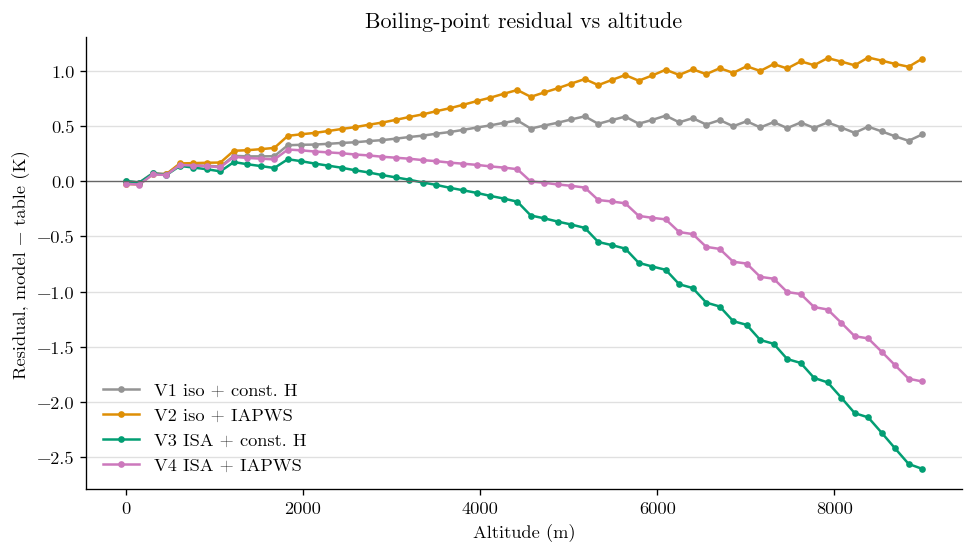

In [15]:
# Band statistics per variant (residual = model - Engineering ToolBox table, K)
for v in VARIANTS:
    print(f"{v}  ({VARIANTS[v][0]} + {VARIANTS[v][1]})")
    for band, s in summary[v].items():
        print(f"  {band:8s} n={s['n']:3d}  bias {s['bias_K']:+.2f} K  MAE {s['mae_K']:.2f} K  max {s['max_abs_K']:.2f} K")

print()
print("V1 - V3 sign:", cross["V1_minus_V3"]["sign"], "| crossings (m):", cross["V1_minus_V3"]["crossings_m"])
print("V2 - V4 sign:", cross["V2_minus_V4"]["sign"], "| crossings (m):", cross["V2_minus_V4"]["crossings_m"])
print("V1 - V2 mean by band (K):", {b: round(x, 3) for b, x in cross["V1_minus_V2_by_band_bias_K"].items()})

# Residual against altitude, one line per variant
roles = {"V1": "baseline", "V2": "other_1", "V3": "other_2", "V4": "other_3"}
names = {"V1": "V1 iso + const. H", "V2": "V2 iso + IAPWS", "V3": "V3 ISA + const. H", "V4": "V4 ISA + IAPWS"}
fig, ax = plt.subplots(figsize=(8, 4.5))
for v in VARIANTS:
    ax.plot(resid_tab[v]["altitude_m"], resid_tab[v]["residual_K"], marker="o", ms=3,
            color=COLOURS[roles[v]], label=names[v])
ax.axhline(0, color="#666666", lw=0.8)
ax.set_xlabel("Altitude (m)")
ax.set_ylabel("Residual, model − table (K)")
ax.set_title("Boiling-point residual vs altitude")
ax.legend()
plt.show()


## Interpretation

**Reading the numbers (60-row subset).**

- **Baseline V1** (isothermal + constant enthalpy) has bias +0.22, +0.50 and +0.50 K across the 0–3, 3–6 and 6–9 km bands, and its largest error is 0.59 K. It stays within 0.6 K over the whole range. The full 119-row run gives +0.23, +0.51 and +0.50 K.
- **V3** (ISA + constant enthalpy) is close to V1 at low altitude, but its bias moves to −1.67 K in the 6–9 km band, with a maximum error of 2.60 K. The full run gives −1.64 K and 2.6 K. The constant-enthalpy shortcut is not the source of the error. The ISA lapse-rate profile is what drives the drift.
- **Crossovers.** V1−V3 and V2−V4 keep one sign across 0–9 km, so no crossover altitude appears. The V1−V2 mean difference grows with altitude: −0.06, −0.28 and −0.55 K by band. This matches the expected behaviour of the constant-enthalpy shortcut.
- **Sensitivity** to the enthalpy (±500 J/mol) and sea-level pressure (±1 kPa) is written to `results/sensitivity.json`.

**What this does and does not show.** These are residuals against the Engineering ToolBox reference curve, whose method is unstated. They are not measurements. The measured-pair comparison has no rows, so this demo says nothing about accuracy against measured boiling points. Because the demo uses 60 of 119 rows, its band statistics differ slightly from the full run.
